# 02 Анализ данных для DurationMod и Convexity

Цель по ТЗ - понять, для каких бумаг можно восстанавливать дюрацию и выпуклость.
Сначала проверяем целевые величины и доступность признаков, затем структуру дней без
сделок. Также проверим простой перенос последней доходности; основные модели дюрации и выпуклости находятся в `03_catboost.ipynb`.

Источники и проверка «было с последующим расчётом стало» находятся в `01_moex_collector.ipynb`.

Далее изучим временные признаки для сценария отсутствия сделки.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("notebooks/price_imputation/data") if Path("notebooks/price_imputation").exists() else Path("data")
bonds = pd.read_parquet(DATA / "bonds.parquet")
market = pd.read_parquet(DATA / "market_data.parquet")
diag = pd.read_parquet(DATA / "calculation_diagnostics.parquet")
market["trade_date"] = pd.to_datetime(market["trade_date"])
market = market.merge(bonds[["ISIN", "SECID"]], left_on="isin", right_on="ISIN", validate="many_to_one")
market = market.merge(diag[["SECID", "TRADEDATE", "ml_eligible"]],
                      left_on=["SECID", "trade_date"], right_on=["SECID", "TRADEDATE"], validate="one_to_one")

## Пропуски, типы, дубликаты и распределения целей

Не смешиваем три источника: опубликованную дюрацию, выпуклость по графику выплат
и приближение для флоатеров. Для целей обучения берём только проверенные обычные
облигации; долю исключений показываем отдельно.

Период: 2022-01-03 - 2026-10-23
Строк: 917912 выпусков: 2664
Дубликаты SECID × дата: 0


,тип,"пропуски, %"
SECID,str,0.00
trade_date,datetime64[us],0.00
settle_date,datetime64[ns],0.00
yield_date,datetime64[us],1.00
face_value,float64,0.00
ytm,float64,11.23
coupon_percent,float64,0.00
coupon_value,float64,0.00
price_clean,float64,0.00
accrued_int,float64,6.19


,rows,missing_duration_pct,missing_convexity_pct,eligible
coupon_type,,,,
fixed,638600,8.90,11.67,392693
floating,209985,0.24,0.00,0
unknown,69118,31.46,100.00,0
zero,209,0.00,0.00,209


,duration_mod,convexity,ytm,face_value
count,392902.000,392902.000,392902.000,3.929020e+05
mean,1.797,8.017,19.355,4.154427e+04
std,1.439,14.793,17.619,6.156727e+05
min,0.000,0.000,-98.940,4.000000e+01
1%,0.073,0.063,4.040,1.000000e+02
5%,0.279,0.314,6.780,4.000000e+02
50%,1.433,3.581,16.830,1.000000e+03
95%,4.851,33.470,33.910,1.000000e+03
99%,7.022,72.643,60.340,2.000000e+05
max,12.445,561.009,968.450,1.000000e+07


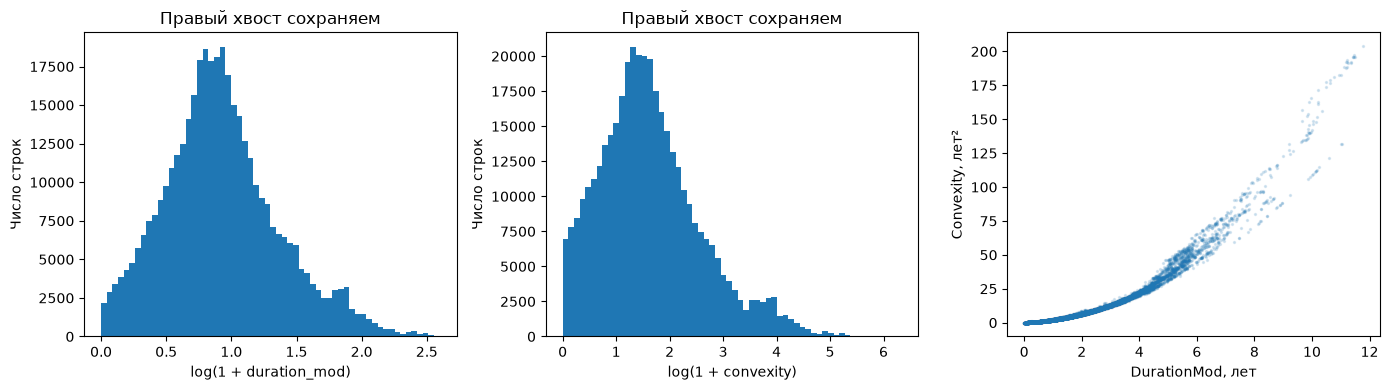

,SECID,trade_date,ytm,duration_mod,convexity
590418,RU000A108BQ1,2025-03-26,-98.81,6.216185,561.009453
776248,RU000A10BQU0,2026-05-22,-98.94,2.843112,275.511067
776249,RU000A10BQU0,2026-05-25,-98.90,2.490660,231.896610
590417,RU000A108BQ1,2025-03-25,-98.06,3.954244,219.463041
693558,RU000A10A844,2025-09-10,5.88,12.052931,211.676249
693563,RU000A10A844,2025-09-17,5.95,11.982907,210.014974
693557,RU000A10A844,2025-09-09,5.99,12.076611,209.840807
693559,RU000A10A844,2025-09-11,5.99,11.999064,209.712111
693556,RU000A10A844,2025-09-08,6.01,11.968372,209.560588
693565,RU000A10A844,2025-09-19,5.99,11.942197,209.069433


In [2]:
from IPython.display import display
model_data = pd.read_parquet(DATA / "model_dataset.parquet")
print("Период:", model_data["trade_date"].min().date(), "-", model_data["trade_date"].max().date())
print("Строк:", len(model_data), "выпусков:", model_data["SECID"].nunique())
print("Дубликаты SECID × дата:", int(model_data.duplicated(["SECID", "trade_date"]).sum()))
display(pd.DataFrame({"тип": model_data.dtypes.astype(str),
                      "пропуски, %": model_data.isna().mean()*100}).round(2))
display(model_data.groupby("coupon_type").agg(rows=("SECID", "size"),
    missing_duration_pct=("duration_mod", lambda x: x.isna().mean()*100),
    missing_convexity_pct=("convexity", lambda x: x.isna().mean()*100),
    eligible=("ml_eligible", "sum")).round(2))
gold = model_data[model_data["ml_eligible"]].copy()
display(gold[["duration_mod", "convexity", "ytm", "face_value"]].describe(
    percentiles=[.01, .05, .5, .95, .99]).round(3))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, target in zip(axes[:2], ["duration_mod", "convexity"]):
    ax.hist(np.log1p(gold[target].dropna()), bins=60)
    ax.set(xlabel=f"log(1 + {target})", ylabel="Число строк", title="Правый хвост сохраняем")
points = gold.sample(min(20000, len(gold)), random_state=42)
axes[2].scatter(points["duration_mod"], points["convexity"], s=2, alpha=.15)
axes[2].set(xlabel="DurationMod, лет", ylabel="Convexity, лет²")
plt.tight_layout()
plt.show()
display(gold.nlargest(10, "convexity")[["SECID", "trade_date", "ytm", "duration_mod", "convexity"]])

## Какие признаки реально доступны

Таблица ниже показывает фактическое покрытие. Рейтинг и сектор отсутствуют;
идентификаторы выпуска и эмитента не передаём модели. Тип купона на историческую дату
иногда неизвестен: оставляем отдельную категорию, а не берём сегодняшний тип как будто
он был известен в прошлом. Доходность будет необязательным признаком, отсутствие
которого отдельно проверим в модели.

In [3]:
feature_columns = ["years_to_maturity", "years_to_yield_date", "coupon_type_asof", "coupon_freq_asof",
                   "coupon_period_days_asof", "coupon_percent", "coupon_value", "currency_asof",
                   "face_value", "ytm", "has_buyback", "is_government"]
coverage = pd.DataFrame({"доступно, %": gold[feature_columns].notna().mean()*100,
                         "уникальных": gold[feature_columns].nunique()})
display(coverage.round(2))
print("Тип купона unknown_at_date, %:", round(gold["coupon_type_asof"].eq("unknown_at_date").mean()*100, 2))
print("Валюта unknown_at_date, %:", round(gold["currency_asof"].eq("unknown_at_date").mean()*100, 2))
feature_columns_saved = pd.Series(feature_columns, name="feature")
feature_columns_saved.to_csv(DATA / "model_features.csv", index=False)

,"доступно, %",уникальных
years_to_maturity,98.05,7918
years_to_yield_date,100.00,6971
coupon_type_asof,100.00,4
coupon_freq_asof,94.03,24
coupon_period_days_asof,94.03,75
coupon_percent,100.00,338
coupon_value,100.00,1619
currency_asof,100.00,5
face_value,100.00,725
ytm,100.00,10588


Тип купона unknown_at_date, %: 31.41
Валюта unknown_at_date, %: 0.0


## Флоатеры: отдельное правило, отдельные выводы

Сравниваем `1 / coupon_freq_asof` с исходной биржевой дюрацией там, где она существует.
Это не обучение CatBoost. Отсутствие независимого наблюдения Convexity не позволяет
подтвердить правило `Convexity = 0`: ноль здесь остаётся допущением кейса.

Большое расхождение с биржевой DURATION означает, что правило не воспроизводит
этот показатель. Оно само по себе не устанавливает истинную чувствительность
цены флоатера к ставке: для такой проверки нужна отдельная модель переоценки купонов.
Не используем биржевую DURATION как автоматическое доказательство верности или
неверности правила 1/f.

Флоатеров, строк: 209985 можно сравнить: 147445


,rows,mae_years,median_abs_error_years
coupon_freq_asof,,,
2.0,18799,1.4221,0.4847
4.0,41687,0.9888,0.9257
5.0,3,5.9965,6.0018
6.0,82,1.9982,1.1147
8.0,21,1.5624,1.5627
10.0,7,3.2651,3.3761
12.0,86326,1.0964,0.9781
13.0,326,2.2474,1.8121
14.0,81,1.5141,1.5038


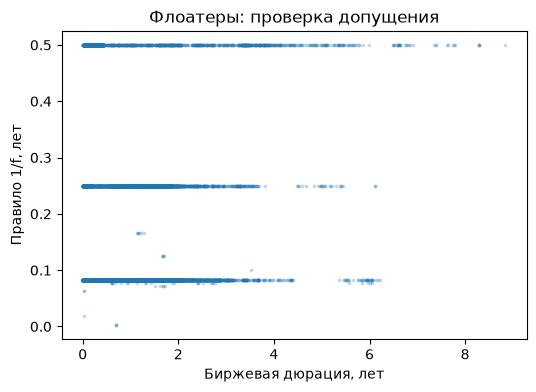

In [4]:
floats = model_data[model_data["coupon_type"].eq("floating")].merge(
    diag[["SECID", "TRADEDATE", "duration_moex"]],
    left_on=["SECID", "trade_date"], right_on=["SECID", "TRADEDATE"], validate="one_to_one")
floats["duration_rule"] = 1 / floats["coupon_freq_asof"].where(floats["coupon_freq_asof"] > 0)
floats["abs_error_years"] = (floats["duration_rule"] - floats["duration_moex"]).abs()
float_check = floats.dropna(subset=["duration_rule", "duration_moex"])
print("Флоатеров, строк:", len(floats), "можно сравнить:", len(float_check))
if len(float_check):
    display(float_check.groupby("coupon_freq_asof").agg(
        rows=("SECID", "size"), mae_years=("abs_error_years", "mean"),
        median_abs_error_years=("abs_error_years", "median")).round(4))
    fig, ax = plt.subplots(figsize=(6, 4))
    sample = float_check.sample(min(10000, len(float_check)), random_state=42)
    ax.scatter(sample["duration_moex"], sample["duration_rule"], s=3, alpha=.2)
    ax.set(xlabel="Биржевая дюрация, лет", ylabel="Правило 1/f, лет", title="Флоатеры: проверка допущения")
    plt.show()
else:
    print("Биржевых значений для независимой проверки правила недостаточно")

## Какие дни считаем торговыми

Берём даты, когда в сохранённой истории TQOB/TQCB была хотя бы одна сделка по рынку.
Период жизни выпуска ограничиваем первой и последней строкой его истории:
до появления бумаги и после конца её истории пропуски не создаём.
Это приближение истории допуска к торгам. Текущая выборка не содержит все выпуски,
которые уже погашены; статистику нельзя переносить на весь рынок с 2022 года.

In [5]:
raw_frames = []
for secid in bonds["SECID"]:
    file = DATA / "history" / f"{secid}.parquet"
    if not file.exists():
        continue
    frame = pd.read_parquet(file)
    if frame.empty:
        continue
    raw_frames.append(frame[["SECID", "TRADEDATE", "NUMTRADES"]])
raw = pd.concat(raw_frames, ignore_index=True)
del raw_frames
raw["TRADEDATE"] = pd.to_datetime(raw["TRADEDATE"])
raw["NUMTRADES"] = pd.to_numeric(raw["NUMTRADES"], errors="coerce")
raw = raw[raw["TRADEDATE"].between(market["trade_date"].min(), market["trade_date"].max())]
if raw.duplicated(["SECID", "TRADEDATE"]).any():
    raise ValueError("Повторные строки выпуска и даты: сначала проверьте торговые сессии")
trading_days = pd.DatetimeIndex(sorted(raw.loc[raw["NUMTRADES"] > 0, "TRADEDATE"].unique()))
life = raw.groupby("SECID")["TRADEDATE"].agg(["min", "max"])
parts = []
for secid, row in life.iterrows():
    days = trading_days[(trading_days >= row["min"]) & (trading_days <= row["max"])]
    parts.append(pd.DataFrame({"SECID": secid, "trade_date": days}))
grid = pd.concat(parts, ignore_index=True)
del parts
grid = grid.merge(market[["SECID", "trade_date", "ytm", "num_trades", "ml_eligible"]],
                  on=["SECID", "trade_date"], how="left", validate="one_to_one")
grid["has_trade"] = grid["num_trades"].fillna(0).gt(0)
grid["has_yield"] = grid["has_trade"] & grid["ytm"].notna()
grid["ml_eligible"] = grid["ml_eligible"].eq(True)
grid["missing_reason"] = np.select(
    [~grid["has_trade"], ~grid["has_yield"], ~grid["ml_eligible"]],
    ["no_trade", "trade_without_yield", "quality_filter"], default="usable")
print("Размер сетки:", grid.shape)
print(grid["missing_reason"].value_counts())
print((grid["missing_reason"].value_counts(normalize=True) * 100).round(2))

Размер сетки: (1556066, 8)
missing_reason
no_trade               638154
quality_filter         421973
usable                 392902
trade_without_yield    103037
Name: count, dtype: int64
missing_reason
no_trade               41.01
quality_filter         27.12
usable                 25.25
trade_without_yield     6.62
Name: proportion, dtype: float64


## Доля пропусков по месяцам и длина промежутков без сделок

             rows  trade_share  yield_share  usable_share
trade_date                                               
2022-01     10196        0.441        0.420           0.0
2022-02      9388        0.431        0.410           0.0
2022-03      4788        0.222        0.206           0.0
2022-04     11172        0.416        0.396           0.0
2022-05      9612        0.411        0.391           0.0
2022-06     11410        0.433        0.413           0.0
2022-07     11651        0.437        0.414           0.0
2022-08     13021        0.439        0.417           0.0
2022-09     12673        0.461        0.436           0.0
2022-10     12240        0.447        0.421           0.0
2022-11     12566        0.468        0.437           0.0
2022-12     13637        0.501        0.455           0.0


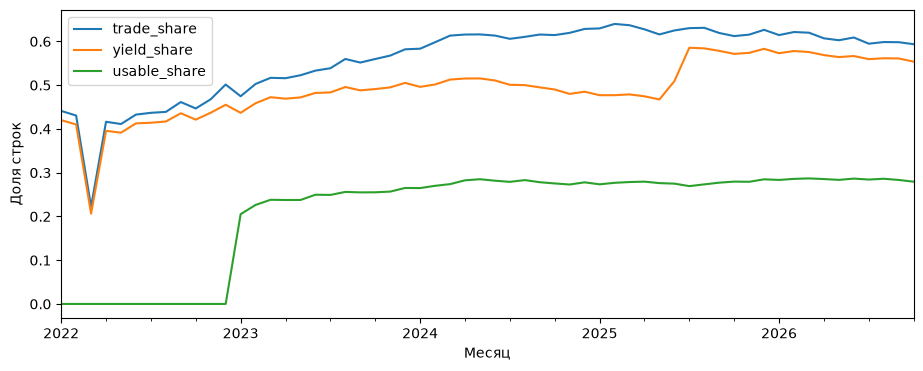

Длина пропусков, торговые дни:
count    62941.0
mean        10.1
std         60.5
min          1.0
50%          2.0
90%         13.0
99%        122.0
max       1205.0
dtype: float64
Первые/последние промежутки ограничены границами загруженной истории


In [6]:
monthly = grid.groupby(grid["trade_date"].dt.to_period("M")).agg(
    rows=("SECID", "size"), trade_share=("has_trade", "mean"),
    yield_share=("has_yield", "mean"), usable_share=("ml_eligible", "mean"))
print(monthly.head(12).round(3))
monthly[["trade_share", "yield_share", "usable_share"]].plot(figsize=(11, 4))
plt.ylabel("Доля строк")
plt.xlabel("Месяц")
plt.show()

grid = grid.sort_values(["SECID", "trade_date"]).reset_index(drop=True)

run_id = grid.groupby("SECID")["has_trade"].cumsum()
gap_lengths = grid.loc[~grid["has_trade"]].groupby(
    [grid.loc[~grid["has_trade"], "SECID"], run_id[~grid["has_trade"]]]).size()
print("Длина пропусков, торговые дни:")
print(gap_lengths.describe(percentiles=[0.5, 0.9, 0.99]).round(1))
print("Первые/последние промежутки ограничены границами загруженной истории")

## Проверка baseline по времени

Последние 20% торговых дат - проверочная часть. Создаём два сценария:

1. Скрываем случайные 10% подходящих наблюдений в проверочной части.
2. Для каждого выпуска скрываем блок из пяти последовательных торговых дней.

В каждом сценарии сначала скрываем значения, затем строим forward fill с `shift(1)`.
Таким образом, baseline использует только более ранние видимые доходности.
Ничего не заполняем из будущего и не используем `bfill`.
Оценка считается только на известных значениях, прошедших фильтр качества.

Средние ошибки чувствительны к очень большим годовым доходностям.
Показываем также медиану и 90-й перцентиль абсолютной ошибки; выбросы не удаляем.

In [7]:
split_date = trading_days[int(len(trading_days) * 0.8)]
print("Проверка начиная с:", split_date.date())
rng = np.random.default_rng(42)
validation = grid["trade_date"].ge(split_date)
candidate = validation & grid["ml_eligible"] & grid["ytm"].notna()
random_mask = candidate & (rng.random(len(grid)) < 0.1)
block_mask = pd.Series(False, index=grid.index)
for secid, group in grid[validation].groupby("SECID", sort=True):
    usable = group.index[group["ml_eligible"] & group["ytm"].notna()]

    usable = usable[group.index.get_indexer(usable) <= len(group) - 5]
    if len(usable) == 0:
        continue
    start_idx = int(rng.choice(usable))
    start_pos = int(group.index.get_loc(start_idx))
    block_mask.loc[group.index[start_pos:start_pos + 5]] = True

results = []
evaluations = []
mask_frames = []

Проверка начиная с: 2025-11-11


In [8]:
for scenario, mask in [("random_10pct", random_mask), ("block_5days", block_mask)]:
    visible = grid["ytm"].where(~mask)

    prediction = visible.groupby(grid["SECID"]).transform(lambda x: x.ffill().shift(1))
    known_date = grid["trade_date"].where(visible.notna())
    last_date = known_date.groupby(grid["SECID"]).transform(lambda x: x.ffill().shift(1))
    hidden = grid.loc[mask, ["SECID", "trade_date"]].copy()
    hidden["scenario"] = scenario
    hidden["is_target"] = candidate[mask].to_numpy()
    mask_frames.append(hidden)
    target_rows = mask & candidate
    scored = target_rows & prediction.notna()
    error = prediction[scored] - grid.loc[scored, "ytm"]
    results.append({"scenario": scenario, "hidden_targets": int(target_rows.sum()),
                    "scored_targets": int(scored.sum()),
                    "coverage_pct": scored.sum() / max(target_rows.sum(), 1) * 100,
                    "mae_pp": error.abs().mean(), "rmse_pp": np.sqrt(error.pow(2).mean()),
                    "median_abs_error_pp": error.abs().median(),
                    "p90_abs_error_pp": error.abs().quantile(0.9)})
    evaluation = grid.loc[target_rows, ["SECID", "trade_date", "ytm"]].rename(columns={"ytm": "target_ytm"})
    evaluation["scenario"] = scenario
    evaluation["prediction"] = prediction[target_rows]
    evaluation["last_observed_date"] = last_date[target_rows]
    evaluation["days_since_observation"] = (evaluation["trade_date"] - evaluation["last_observed_date"]).dt.days
    evaluations.append(evaluation)
    assert (last_date[scored] < grid.loc[scored, "trade_date"]).all()

validation_masks = pd.concat(mask_frames, ignore_index=True)
baseline_scores = pd.DataFrame(results)
baseline_validation = pd.concat(evaluations, ignore_index=True)
print(baseline_scores.round(4).to_string(index=False))
print("MAE и RMSE в процентных пунктах годовой доходности, не в процентах цены")

baseline_validation["abs_error_pp"] = (baseline_validation["prediction"] - baseline_validation["target_ytm"]).abs()
print("Крупнейшие ошибки - отдельно проверяем скачки доходности и старые наблюдения:")
print(baseline_validation.nlargest(10, "abs_error_pp").to_string(index=False))

    scenario  hidden_targets  scored_targets  coverage_pct  mae_pp  rmse_pp  median_abs_error_pp  p90_abs_error_pp
random_10pct           17532           17510       99.8745  1.1481  12.6363                 0.23             1.580
 block_5days            4464            4415       98.9023  1.1230   4.9000                 0.31             1.986
MAE и RMSE в процентных пунктах годовой доходности, не в процентах цены
Крупнейшие ошибки - отдельно проверяем скачки доходности и старые наблюдения:
       SECID trade_date  target_ytm     scenario  prediction last_observed_date  days_since_observation  abs_error_pp
RU000A106631 2026-05-08       29.23 random_10pct      856.51         2026-05-04                     4.0        827.28
RU000A106631 2026-05-11       30.19 random_10pct      856.51         2026-05-04                     7.0        826.32
RU000A1099P0 2026-08-17      501.16 random_10pct       20.83         2026-08-14                     3.0        480.33
RU000A105H98 2026-07-08       30.

## Результаты для следующего этапа

Сетка содержит только исходные доходности и пропуски. Предсказания baseline сохраняем
отдельно и не добавляем к обучающим целям. Таблица проверки содержит `target_ytm`:
это ответ для оценки ошибки, его нельзя включать в признаки модели.

Этот baseline - отдельная предварительная проверка доходности. В ноутбуке 03
используется другое разбиение: train, validation, calibration и test для восстановления метрик. Для будущего прогноза котировок потребуются признаки на ту же дату без скрытых значений проверочной выборки.
Нельзя брать текущий справочник и будущие купоны как исторически известные признаки.
Полные маски скрытия для обоих сценариев сохранены в `validation_masks.parquet`,
включая скрытые дни без подходящей обучающей цели. Основная модель в ноутбуке 03 оценивает другие цели: дюрацию и выпуклость.

In [9]:
grid.to_parquet(DATA / "yield_grid.parquet", index=False)
monthly.to_csv(DATA / "missingness_monthly.csv")
baseline_scores.to_csv(DATA / "baseline_scores.csv", index=False)
validation_masks.to_parquet(DATA / "validation_masks.parquet", index=False)
baseline_validation.to_parquet(DATA / "baseline_validation.parquet", index=False)
baseline_validation.nlargest(1000, "abs_error_pp").to_csv(DATA / "baseline_worst_errors.csv", index=False)
print("Сохранены yield_grid.parquet, missingness_monthly.csv, baseline_scores.csv, baseline_validation.parquet")

Сохранены yield_grid.parquet, missingness_monthly.csv, baseline_scores.csv, baseline_validation.parquet


## Что показал анализ и что меняем в следующем ноутбуке

Выводы написаны по сохранённым результатам. При обновлении данных их нужно пересмотреть.

Сетка содержит 1 556 066 строк. В 41,0% строк сделок нет, ещё в 6,6% сделка есть,
но доходность не указана. Поэтому отсутствие доходности нельзя всегда трактовать
как отсутствие торговли.

Для обучения отобраны 392 902 строки из 1024 выпусков. У выпуклости длинный правый
хвост: медиана 3,581, а 99-й перцентиль 72,643. Это объясняет выбор log-преобразования
целей. Исторический тип купона неизвестен у 31,4% строк; такие значения оставлены
отдельной категорией.

Строки одной облигации зависимы во времени. Проверять модель случайным перемешиванием
строк было бы слишком оптимистично, поэтому в третьем ноутбуке используются
разделение по датам и отдельная проверка на новых эмитентах.

## Дополнительный анализ: цена, динамика и временные признаки

Дюрация и выпуклость зависят от всего графика выплат, а не только от одной цены.
При известном графике можно пройти путь цена с последующим расчётом доходность с последующим расчётом DurationMod/Convexity.
Проверим, согласуется ли эта цепочка с фактическими котировками, прежде чем обучать модель.

Рейтинги/сектора не придумываем. Добавляем лаги, скользящие средние и волатильность,
EWMA, давность котировки и текущий рынок похожих бумаг. Здесь исследуем доступность окон и рыночных признаков.
В основную модель из ноутбука 03 они пока не включены.

,rows,median,p90,p99
currency_asof,,,,
CHF,1005,70.4910,125.4087,143.9037
CNY,12326,6.1417,20.4131,43.8442
EUR,4056,74.8005,179.4842,365.2130
RUB,332357,0.0484,0.1586,3.0160
USD,42949,62.6211,183.3699,355.7006


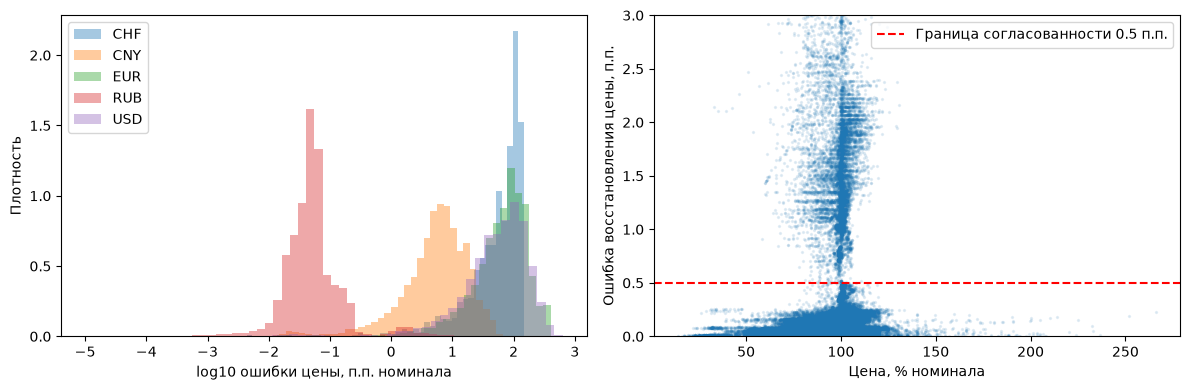

Согласованная рублёвая выборка: 282915 из 332566 строк


In [10]:
price_analysis = model_data.merge(diag[["SECID", "TRADEDATE", "price_dirty_calc", "offer_price_assumed"]],
    left_on=["SECID", "trade_date"], right_on=["SECID", "TRADEDATE"], validate="one_to_one")
price_analysis["dirty_quote"] = price_analysis["price_clean"]/100*price_analysis["face_value"] + price_analysis["accrued_int"]
price_analysis["price_gap_pp"] = (price_analysis["price_dirty_calc"]-price_analysis["dirty_quote"]).abs()/price_analysis["face_value"]*100
valid_price = price_analysis[price_analysis["ml_eligible"]].copy()
display(valid_price.groupby("currency_asof")["price_gap_pp"].agg(
    rows="count", median="median", p90=lambda x:x.quantile(.9), p99=lambda x:x.quantile(.99)).round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for currency, group in valid_price.groupby("currency_asof"):
    axes[0].hist(np.log10(group["price_gap_pp"].clip(lower=1e-5)), bins=50, alpha=.4, label=currency, density=True)
axes[0].set(xlabel="log10 ошибки цены, п.п. номинала", ylabel="Плотность")
axes[0].legend()
rub = valid_price[valid_price["currency_asof"].eq("RUB")].copy()
axes[1].scatter(rub["price_clean"], rub["price_gap_pp"], s=2, alpha=.1)
axes[1].axhline(.5, color="red", linestyle="--", label="Граница согласованности 0.5 п.п.")
axes[1].set(xlabel="Цена, % номинала", ylabel="Ошибка восстановления цены, п.п.", ylim=(0, 3))
axes[1].legend()
plt.tight_layout()
plt.show()
benchmark_cohort = rub[rub["price_gap_pp"].le(.5) & ~rub["offer_price_assumed"] & rub["dirty_quote"].gt(0)].copy()
benchmark_cohort[["SECID", "trade_date"]].to_parquet(DATA / "price_benchmark_cohort.parquet", index=False)
print("Согласованная рублёвая выборка:", len(benchmark_cohort), "из", len(rub), "строк")

Для валютных бумаг обнаружены большие расхождения расчётной и наблюдаемой цены. Для подробной проверки цен выделена рублёвая выборка. Валютные наблюдения требуют отдельной сверки валюты выплат и НКД. Граница 0,5 п.п. номинала используется только для этой проверки согласованности цен, а не для обучения основной модели.

## Функции признаков: только наблюдения, доступные к моменту оценки

Все собственные окна начинаются с `shift(1)`. Среднее рынка за текущий день исключает
саму бумагу. Истинные значения скрываем до `ffill`, rolling и EWMA. Будущих значений и
`bfill` нет. Скользящее окно идёт по календарю рыночных сессий, включая дни без сделок.
Функция ниже нужна для исследования временных признаков. Основная модель в ноутбуке 03 пока использует характеристики облигации без этих окон.

In [11]:
STATIC_FEATURES = ["years_to_maturity", "years_to_yield_date", "coupon_type_asof", "coupon_freq_asof",
                   "coupon_period_days_asof", "coupon_percent", "coupon_value", "currency_asof",
                   "face_value", "has_buyback", "is_government"]
HISTORY_COLUMNS = ["price_clean", "ytm", "duration_mod", "convexity"]

In [12]:
def build_history_features(frame, hidden=None):
    hidden = pd.Series(False, index=frame.index) if hidden is None else hidden.reindex(frame.index, fill_value=False)
    features = frame[STATIC_FEATURES].copy()
    sec = frame["SECID"]
    visible = {}
    for col in HISTORY_COLUMNS:
        visible[col] = pd.to_numeric(frame[col], errors="coerce").where(~hidden)

        known = visible[col].groupby(sec, sort=False).ffill()
        features[f"{col}_lag1"] = known.groupby(sec, sort=False).shift(1)
    for col in ["price_clean", "ytm"]:
        known = visible[col].groupby(sec, sort=False).ffill()
        for lag in [5, 20]:
            features[f"{col}_lag{lag}"] = known.groupby(sec, sort=False).shift(lag)
        past = visible[col].groupby(sec, sort=False).shift(1)
        for window in [5, 20, 60]:
            rolling = past.groupby(sec, sort=False).rolling(window, min_periods=3)
            features[f"{col}_mean{window}"] = rolling.mean().reset_index(level=0, drop=True).reindex(frame.index)
            features[f"{col}_std{window}"] = rolling.std().reset_index(level=0, drop=True).reindex(frame.index)
        features[f"{col}_ewm20"] = past.groupby(sec, sort=False).transform(
            lambda values: values.ewm(span=20, min_periods=3, adjust=False).mean())
        features[f"{col}_change5"] = features[f"{col}_lag1"] - features[f"{col}_lag5"]
    last_quote_date = frame["trade_date"].where(visible["price_clean"].notna()).groupby(sec, sort=False).ffill()
    last_quote_date = last_quote_date.groupby(sec, sort=False).shift(1)
    features["days_since_quote"] = (frame["trade_date"] - last_quote_date).dt.days
    past_return = np.log(visible["price_clean"].where(visible["price_clean"] > 0)).groupby(sec, sort=False).diff()
    past_return = past_return.groupby(sec, sort=False).shift(1)
    features["return_vol20"] = past_return.groupby(sec, sort=False).rolling(20, min_periods=3).std().reset_index(level=0, drop=True).reindex(frame.index)

    bucket = pd.cut(frame["years_to_yield_date"], [-np.inf, .25, .5, 1, 2, 3, 5, 7, 10, 20, np.inf]).astype(str)
    keys = [frame["trade_date"], frame["currency_asof"].fillna("unknown"), bucket]
    for col in ["price_clean", "ytm"]:
        values = visible[col]
        sums = values.groupby(keys, dropna=False).transform("sum") - values.fillna(0)
        counts = values.groupby(keys, dropna=False).transform("count") - values.notna().astype(int)
        features[f"peer_{col}_today"] = sums / counts.where(counts > 0)
        if col == "ytm":
            features["peer_count"] = counts
            previous_market = features["peer_ytm_today"].where(values.notna()).groupby(sec, sort=False).ffill()
            previous_market = previous_market.groupby(sec, sort=False).shift(1)
            features["market_yield_change"] = features["peer_ytm_today"] - previous_market
    gov_y = visible["ytm"].where(frame["is_government"].eq(1))
    sums = gov_y.groupby(keys, dropna=False).transform("sum") - gov_y.fillna(0)
    counts = gov_y.groupby(keys, dropna=False).transform("count") - gov_y.notna().astype(int)
    features["gov_yield_today"] = sums / counts.where(counts > 0)
    features["weekday"] = frame["trade_date"].dt.day_of_week
    features["month_sin"] = np.sin(2*np.pi*frame["trade_date"].dt.month/12)
    features["month_cos"] = np.cos(2*np.pi*frame["trade_date"].dt.month/12)

    for col in features.columns.difference(["coupon_type_asof", "currency_asof"]):
        features[col] = pd.to_numeric(features[col], errors="coerce").replace([np.inf, -np.inf], np.nan).astype("float32")
    return features

In [13]:
def make_history_grid(data, grid):

    columns = ["SECID", "trade_date"] + STATIC_FEATURES + HISTORY_COLUMNS
    if data.duplicated(["SECID", "trade_date"]).any():
        raise ValueError("Дубли до построения временных признаков")
    result = grid[["SECID", "trade_date"]].merge(data[columns], on=["SECID", "trade_date"],
                                                   how="left", validate="one_to_one")
    return result.sort_values(["SECID", "trade_date"]).reset_index(drop=True)

,feature,missing_pct
0,years_to_maturity,17.04
1,years_to_yield_date,17.04
2,coupon_type_asof,17.04
3,coupon_freq_asof,21.88
4,coupon_period_days_asof,21.88
5,coupon_percent,17.04
6,coupon_value,17.04
7,currency_asof,17.04
8,face_value,17.04
9,has_buyback,17.04


Проверка утечки собственной текущей строки: PASS


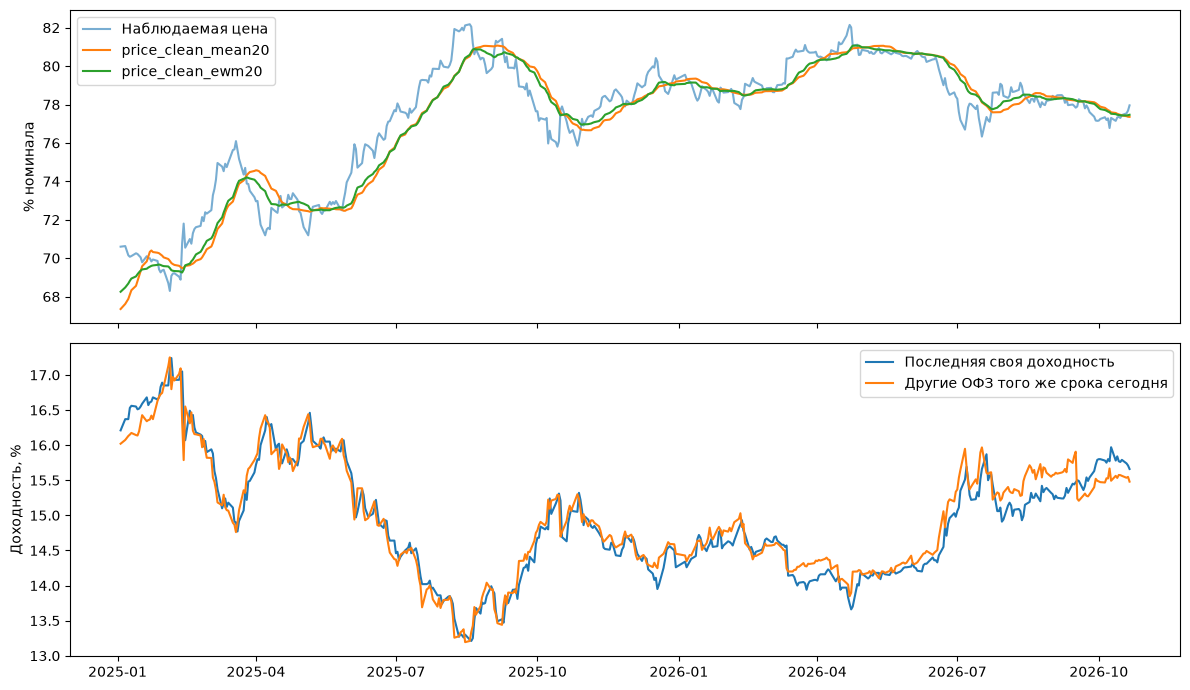

,price_lag1_corr,return_lag1_corr,observations
count,680.000,680.000,680.000
mean,0.938,-0.150,516.490
std,0.112,0.200,355.675
min,0.077,-0.950,100.000
25%,0.937,-0.266,228.000
50%,0.976,-0.148,392.500
75%,0.992,-0.020,746.500
max,0.999,0.638,1205.000


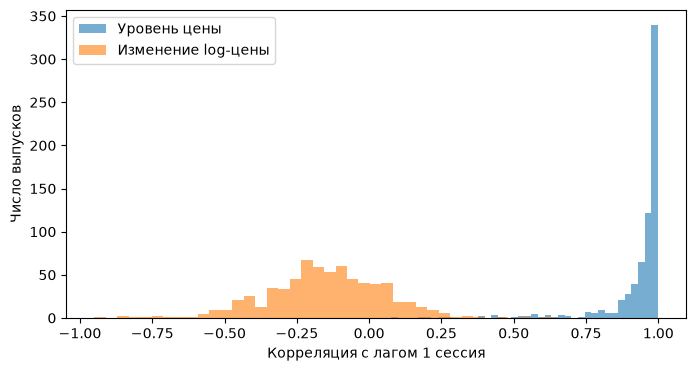

In [14]:
eda_secids = set(benchmark_cohort["SECID"])
eda_history = make_history_grid(model_data[model_data["SECID"].isin(eda_secids)], grid[grid["SECID"].isin(eda_secids)])
eda_features = build_history_features(eda_history)
display(pd.DataFrame({"feature": eda_features.columns,
                      "missing_pct": eda_features.isna().mean().to_numpy()*100}).round(2))

control_idx = eda_history.index[eda_history["price_clean"].notna()][1000]
control_frame = eda_history.iloc[:control_idx+1].copy()
x_before = build_history_features(control_frame).loc[control_idx]
control_frame.loc[control_idx, HISTORY_COLUMNS] = np.nan
x_after = build_history_features(control_frame).loc[control_idx]
pd.testing.assert_series_equal(x_before, x_after)
print("Проверка утечки собственной текущей строки: PASS")
example = eda_history[(eda_history["SECID"]=="SU26218RMFS6") & eda_history["trade_date"].ge("2025-01-01")]
if len(example):
    fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
    axes[0].plot(example["trade_date"], example["price_clean"], label="Наблюдаемая цена", alpha=.6)
    for col in ["price_clean_mean20", "price_clean_ewm20"]:
        axes[0].plot(example["trade_date"], eda_features.loc[example.index, col], label=col)
    axes[0].set(ylabel="% номинала")
    axes[0].legend()
    axes[1].plot(example["trade_date"], eda_features.loc[example.index, "ytm_lag1"], label="Последняя своя доходность")
    axes[1].plot(example["trade_date"], eda_features.loc[example.index, "gov_yield_today"], label="Другие ОФЗ того же срока сегодня")
    axes[1].set(ylabel="Доходность, %")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

autocorr_rows = []
for secid, group in eda_history.groupby("SECID", sort=False):
    values = group["price_clean"]
    changes = np.log(values.where(values>0)).diff()
    if values.notna().sum() >= 100:
        autocorr_rows.append({"SECID": secid, "price_lag1_corr": values.autocorr(1),
                              "return_lag1_corr": changes.autocorr(1), "observations": int(values.notna().sum())})
autocorr = pd.DataFrame(autocorr_rows)
display(autocorr.describe().round(3))
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(autocorr["price_lag1_corr"].dropna(), bins=40, alpha=.6, label="Уровень цены")
ax.hist(autocorr["return_lag1_corr"].dropna(), bins=40, alpha=.6, label="Изменение log-цены")
ax.legend()
ax.set(xlabel="Корреляция с лагом 1 сессия", ylabel="Число выпусков")
plt.show()
autocorr.to_csv(DATA / "price_autocorrelation.csv", index=False)

In [15]:
feature_staleness = eda_features.groupby(pd.cut(eda_features["days_since_quote"], [0, 1, 3, 7, 30, np.inf], include_lowest=True), observed=True).agg(
    rows=("days_since_quote", "size"), window20_available=("price_clean_mean20", lambda x:x.notna().mean()),
    market_today_available=("peer_ytm_today", lambda x:x.notna().mean()))
display(feature_staleness.round(3))
feature_staleness.to_csv(DATA / "feature_coverage_by_staleness.csv")

,rows,window20_available,market_today_available
days_since_quote,,,
"(-0.001, 1.0]",281248,0.992,0.964
"(1.0, 3.0]",82420,0.978,0.902
"(3.0, 7.0]",20287,0.853,0.468
"(7.0, 30.0]",19446,0.412,0.115
"(30.0, inf]",19374,0.007,0.031


## Связь с обучением

Высокая корреляция уровней цены не доказывает предсказуемость её изменений.
Лаги и окна здесь исследуются отдельно. В ноутбуке 03 решается более узкая задача:
восстановление дюрации и выпуклости по характеристикам облигации.
Добавлять временные признаки в рабочую модель стоит после отдельного сравнения
с простым использованием последнего известного значения.

## Как меняется временной ряд

Для примера возьмём выпуск с самой длинной историей в согласованной рублёвой выборке.
Сравним исходную цену с окнами 5, 20 и 60 сессий. Средние и волатильность построены
по прошлым данным: текущая котировка в них не входит. Пустое окно не заполняем нулём.

Автокорреляцию посмотрим отдельно для уровня цены и изменения log-цены.
Высокая связь соседних уровней часто объясняется медленным изменением цены.
Для прогноза важнее, сохраняется ли связь у изменений.

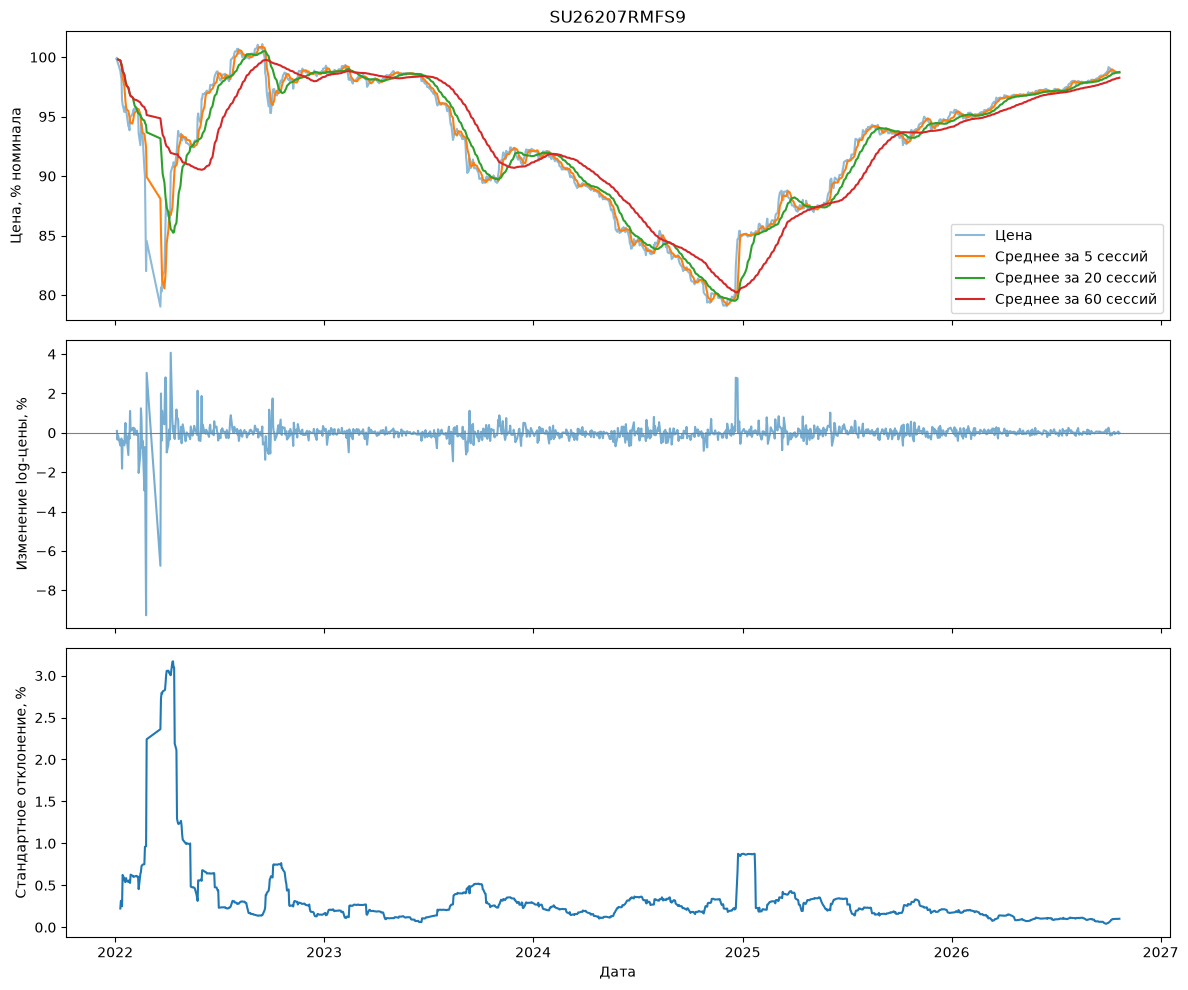

In [16]:
example_secid = eda_history.groupby("SECID")["price_clean"].count().idxmax()
series = eda_history[eda_history["SECID"].eq(example_secid)]
series_features = eda_features.loc[series.index]
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
axes[0].plot(series["trade_date"], series["price_clean"], alpha=.5, label="Цена")
for window in [5, 20, 60]:
    axes[0].plot(series["trade_date"], series_features[f"price_clean_mean{window}"], label=f"Среднее за {window} сессий")
axes[0].set(title=example_secid, ylabel="Цена, % номинала")
axes[0].legend()
log_returns = np.log(series["price_clean"].where(series["price_clean"] > 0)).diff()
axes[1].plot(series["trade_date"], log_returns * 100, alpha=.6)
axes[1].axhline(0, color="gray", linewidth=.8)
axes[1].set(ylabel="Изменение log-цены, %")
axes[2].plot(series["trade_date"], series_features["return_vol20"] * 100)
axes[2].set(ylabel="Стандартное отклонение, %", xlabel="Дата")
plt.tight_layout()
plt.show()

,series,lag,bonds,median,q25,q75
0,log_return,1,666,-0.146,-0.261,-0.018
1,log_return,2,659,-0.005,-0.060,0.053
2,log_return,5,656,0.002,-0.041,0.056
3,log_return,10,656,-0.007,-0.048,0.039
4,log_return,20,655,0.005,-0.042,0.046
5,price,1,679,0.976,0.937,0.992
6,price,2,676,0.959,0.900,0.984
7,price,5,676,0.916,0.815,0.965
8,price,10,673,0.843,0.681,0.936
9,price,20,672,0.717,0.455,0.886


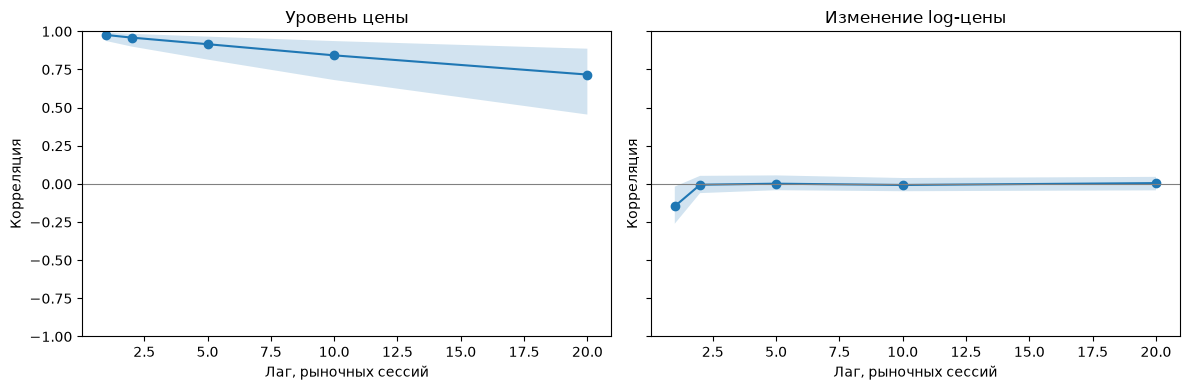

In [17]:
lag_rows = []
for secid, group in eda_history.groupby("SECID", sort=False):
    prices = group["price_clean"]
    returns = np.log(prices.where(prices > 0)).diff()
    if prices.notna().sum() < 100:
        continue
    for lag in [1, 2, 5, 10, 20]:
        for name, values in [("price", prices), ("log_return", returns)]:
            pairs = pd.concat([values, values.shift(lag)], axis=1).dropna()
            if len(pairs) >= 30 and pairs.nunique().min() > 1:
                lag_rows.append({"SECID": secid, "series": name, "lag": lag,
                                 "correlation": pairs.iloc[:, 0].corr(pairs.iloc[:, 1]), "pairs": len(pairs)})
lag_correlations = pd.DataFrame(lag_rows)
lag_summary = lag_correlations.groupby(["series", "lag"])["correlation"].agg(
    bonds="count", median="median", q25=lambda x: x.quantile(.25), q75=lambda x: x.quantile(.75)).reset_index()
display(lag_summary.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, name in zip(axes, ["price", "log_return"]):
    values = lag_summary[lag_summary["series"].eq(name)]
    ax.plot(values["lag"], values["median"], marker="o")
    ax.fill_between(values["lag"], values["q25"], values["q75"], alpha=.2)
    ax.axhline(0, color="gray", linewidth=.8)
    ax.set(title="Уровень цены" if name == "price" else "Изменение log-цены",
           xlabel="Лаг, рыночных сессий", ylabel="Корреляция", ylim=(-1, 1))
plt.tight_layout()
plt.show()
lag_correlations.to_csv(DATA / "price_lag_correlations.csv", index=False)

Корреляция цены с её значением за предыдущую сессию в среднем по выпускам очень
высока: медиана 0,976. Но для изменений log-цены она составляет -0,146, а на более
длинных лагах близка к нулю. Плавность уровня цены сама по себе не означает,
что её следующее изменение легко предсказать.

Окна 5, 20 и 60 сессий показывают разную скорость реакции на движения рынка.
Короткое окно быстрее реагирует на изменения, длинное сильнее сглаживает ряд.
Пики волатильности помогают выделить периоды, когда простое использование последней
котировки может давать большую ошибку. Полоса на графике корреляций показывает
разброс между выпусками, а не доверительный интервал.